# KBM width collapse: GFTM error against the Hermite-basis width mismatch $s$

Fusion_PhD-qp5.27. No new runs: the `qp5.24` leaves (`kbm_free/gal{F,T}_w<W>_nb<N>_nx<X>`, GS2-KBM samples of R3, M1, R4)
against the `kbm_free` GS2 cubes, loaded as in `gftm_galerkin_field_width_selection.ipynb`.

**Theory under test.** A Gaussian $\phi \propto e^{-\theta^2/2\sigma^2}$ expanded in $h_n(\theta/W)$ has even coefficients
$c_{2k}^2 \propto \binom{2k}{k}(r^2/4)^k$ with $r = (s^2-1)/(s^2+1)$, $s = \sigma/W$ (Tang 1993, Eq. 3.14). Since
$\sum_k \binom{2k}{k}(x/4)^k = (1-x)^{-1/2}$, the relative $L^2$ error after $N$ functions ($K = \lceil N/2 \rceil$ even ones) is exactly
$$\epsilon_N(s) = \Big[1 - \sqrt{1-r^2}\,\sum_{k<K}\binom{2k}{k}(r^2/4)^k\Big]^{1/2} \sim |r|^{N/2},$$
so $N_\epsilon(s) \approx 2\ln(1/\epsilon)/\ln(1/|r|) \approx \max(s^2, s^{-2})\ln(1/\epsilon)$. $|r|$ is unchanged by $s \to 1/s$:
the prediction is symmetric in $\log s$. For an odd mode ($x e^{-x^2/2}$-like $A_\parallel$) the odd coefficients follow the same $r^k$ law.

**Matched width.** pyro's `Extent` $\theta_{95}$ is the equal-tail span holding 95% of $\int|\phi|^2 d\theta$ (2.5% to 97.5% of the
cumulative). For the Gaussian $|\phi|^2 \propto e^{-\theta^2/\sigma^2}$, $\theta_{95} = 2 \times 1.96\,\sigma/\sqrt{2} = 2.772\,\sigma$, so the
Gaussian-matched width is $W^* = \theta_{95}/2.772 = 0.361\,\theta_{95}$. Here $W^* = c\,\theta_{95}(\phi_{\rm GS2})$ with one fitted $c$, and $s = W/W^*$.

In [1]:
from pathlib import Path
import os
import json
from math import comb
from multiprocessing import get_context
import warnings
from dotenv import load_dotenv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter
import pyrokinetics
from pyrokinetics import PyroHypercube
from pyrokinetics.diagnostics.extent import Extent
from pyrokinetics.local_geometry.metric import MetricTerms

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "pyproject.toml").is_file() and (path / "notebooks").is_dir())
plt.style.use(ROOT / "src/general_analysis/paper.mplstyle")
plt.rcParams.update({"font.size": 17, "axes.labelsize": 19, "axes.titlesize": 19, "legend.fontsize": 14,
                     "xtick.labelsize": 16, "ytick.labelsize": 16})     # slide-ready
load_dotenv(ROOT / "local.env", override=True)
warnings.filterwarnings("ignore")
print("pyrokinetics", pyrokinetics.__version__)

analysis_name = "kbm_width_collapse"
plots_dir = ROOT / "Plots" / analysis_name
plots_dir.mkdir(parents=True, exist_ok=True)
gs2_root = Path(os.environ["GK_DATA_ROOT"]).expanduser() / "GS2" / "Runs" / "LATIN_HYPERCUBE"
# GyroRun wrote the qp5.24 leaves to the scratch tree; there is no copy under GK_DATA_ROOT
gftm_root = Path(os.environ["GYRO_DATA_OUTPUT"]) / "GFTM" / "Runs" / "LATIN_HYPERCUBE"
cases = os.environ.get("CASES", "R3 M1 R4").split()
arms = {"F": "stock", "T": "Galerkin"}
nbasis_all = [2, 4, 8, 16, 64]          # NXGRID 32; NBASIS 64 at NXGRID 65
nbasis_colours = dict(zip(nbasis_all, plt.cm.viridis(np.linspace(0, 0.9, len(nbasis_all)))))
fraction = 0.95
gaussian_c = 1 / (2 * 1.96 / np.sqrt(2))   # W* / theta95 for a Gaussian phi
n_workers = int(os.environ.get("SLURM_CPUS_PER_TASK", 4))


def log_xticks(ax, ticks):
    ax.set_xticks(ticks)
    ax.xaxis.set_major_formatter(StrMethodFormatter("{x:g}"))
    ax.minorticks_off()


def gaussian_error(s, nbasis):
    # exact relative L2 error of the first nbasis Hermite functions on a Gaussian of width mismatch s
    r_squared = ((s ** 2 - 1) / (s ** 2 + 1)) ** 2
    kept = sum(comb(2 * k, k) * (r_squared / 4) ** k for k in range((nbasis + 1) // 2))
    return np.sqrt(np.clip(1 - np.sqrt(1 - r_squared) * kept, 0, None))


def n_epsilon(s, eps):
    # continuous N at which |r|^(N/2) = eps
    return 2 * np.log(1 / eps) / np.log(np.abs((s ** 2 + 1) / (s ** 2 - 1)))

pyrokinetics 0.9.2.dev153+g3290c692


## GFTM leaves
One `PyroHypercube` per leaf (720 leaves, read in a process pool), dominant mode, pyro `Extent` of $\phi$. Settings from GyroRun's
`manifest.json` `code_flags` (audited 128 400/128 400 against `out.gftm.localdump` in Fusion_PhD `results/gftm_galerkin_field`).
A run with no unstable mode has $\gamma = 0$, $\omega = 0$ (as section 5 of the parent notebook) and no extent.

In [2]:
def load_leaf(leaf):
    gftm_scan = PyroHypercube(pyroscan_json=leaf / "pyroscan.json", load_base_pyro=True)
    gftm_scan.load_gk_output(netcdf_file=leaf / "pyroscan.nc")
    Extent(gftm_scan.gk_output, fraction=fraction)
    flags = json.loads((leaf / "manifest.json").read_text())["code_flags"]
    arm = "T" if flags["FIELD_GALERKIN"] else "F"
    assert leaf.name.startswith(f"gal{arm}_") and f"_nb{int(flags['NBASIS_MAX'])}_" in leaf.name and float(flags["FILTER"]) == 0.5
    gftm_output = gftm_scan.gk_output.data.set_index(sample="sample_name")
    growth = gftm_output.growth_rate.pint.dequantify()
    # IBRANCH -1: GFTM ranks the modes by growth rate, so mode 0 is the dominant one
    assert int(flags["IBRANCH"]) == -1 and (growth.fillna(-np.inf).argmax("mode") == 0).all()
    dominant = gftm_output.isel(mode=0)
    gamma = growth.isel(mode=0).clip(min=0).fillna(0).values
    unstable = gamma > 0
    return pd.DataFrame(dict(case=leaf.parent.parent.name, arm=arm, nbasis=int(flags["NBASIS_MAX"]), width=round(float(flags["WIDTH"]), 4),
                             sample=gftm_output.sample.values.astype(str), gamma=gamma,
                             omega=np.where(unstable, dominant.mode_frequency.pint.dequantify().values, 0.0),
                             extent=np.where(unstable, dominant.extent.sel(field="phi").pint.dequantify().values, np.nan)))


leaves = [leaf for case in cases for leaf in sorted((gftm_root / case / "kbm_free").glob("gal*_nb*"))]
with get_context("fork").Pool(n_workers) as pool:
    gftm = pd.concat(pool.map(load_leaf, leaves, chunksize=4), ignore_index=True)
widths = np.sort(gftm.width.unique())
print("leaves:", len(leaves), "| runs:", len(gftm), "| widths:", len(widths), widths.min(), "-", widths.max())
print(gftm.groupby("case")["sample"].nunique().to_dict())

leaves: 720 | runs: 128400 | widths: 24 0.2 - 4.0
{'M1': 140, 'R3': 187, 'R4': 208}


## GS2 reference: $\gamma$, $\omega$ and per-field $\theta_{95}$
The `kbm_free` GS2 cube, samples paired by `sample_name`. The cube holds time-averaged $|\phi|^2$, $|A_\parallel|^2$, $|B_\parallel|^2$
(`eigenfunctions_squared`, NaN outside each sample's own $\theta$ grid). $\theta_{95}$ of each field is pyro's `Extent` rule on that field
alone. For $A_\parallel$, odd and double-peaked on a KBM, the equal-tail span covers both lobes, so it is the full width of the mode, not
of one lobe. GFTM's third field is $\sigma = \delta B_\parallel/(k_\perp\rho)$ (results/gftm_bpar_extent); its GS2 counterpart is
$|B_\parallel|^2/k_\perp^2$ with $k_\perp(\theta)$ from pyro `MetricTerms(...).k_perp(ky=1)` on each sample's geometry (only its shape matters).
**Caveat:** `MetricTerms` uses the geometric angle, GS2 its own $\theta$; they agree at multiples of $\pi$.

In [3]:
def gs2_sample(args):
    case, name, power = args
    row = dict(case=case, sample=name)
    for field in ("phi", "apar", "bpar"):
        row[f"theta95_{field}"] = float(Extent._compute(power.sel(field=field).dropna("theta"), fraction)[0])
    theta_metric, k_perp = MetricTerms(gs2_scans[case].sample_pyro(name).local_geometry, ntheta=256).k_perp(ky=1.0, theta0=0.0, nperiod=6)
    bpar = power.sel(field="bpar").dropna("theta")
    k_perp = np.interp(bpar.theta.values, np.asarray(getattr(theta_metric, "m", theta_metric)), np.asarray(getattr(k_perp, "m", k_perp)))
    row["theta95_sigma"] = float(Extent._compute(bpar / k_perp ** 2, fraction)[0])
    return row


gs2_scans, gs2_rows, gs2_extents = {}, [], []
for case in cases:
    names = np.sort(gftm[gftm.case == case]["sample"].unique())
    gs2_scans[case] = PyroHypercube(pyroscan_json=gs2_root / case / "kbm_free" / "pyroscan.json", load_base_pyro=True)
    gs2_scans[case].load_gk_output(netcdf_file=gs2_root / case / "kbm_free" / "pyroscan.nc")
    gs2_output = gs2_scans[case].gk_output.data.set_index(sample="sample_name").sel(sample=names)
    assert (gs2_output.growth_rate_tolerance.pint.dequantify().values < 0.05).all()
    gs2_rows.append(pd.DataFrame(dict(case=case, sample=names, gamma_gs2=gs2_output.growth_rate.pint.dequantify().values,
                                      omega_gs2=gs2_output.mode_frequency.pint.dequantify().values,
                                      ky=gs2_output.ky.pint.dequantify().values)))
    power = gs2_output.eigenfunctions_squared.isel(kx=0).pint.dequantify().load()
    with get_context("fork").Pool(n_workers) as pool:
        gs2_extents += pool.map(gs2_sample, [(case, name, power.sel(sample=name)) for name in names])
gs2 = pd.concat(gs2_rows).merge(pd.DataFrame(gs2_extents), on=["case", "sample"])
assert (gs2.gamma_gs2 > 0).all()
print(gs2.groupby("case")[["theta95_phi", "theta95_apar", "theta95_bpar", "theta95_sigma"]].median().round(2).to_string())

data = gftm.merge(gs2, on=["case", "sample"], validate="many_to_one")
data["gamma_error"] = np.abs(data.gamma - data.gamma_gs2) / data.gamma_gs2
data["omega_error"] = np.abs(data.omega - data.omega_gs2)
data["extent_error"] = np.abs(np.log10(data.extent / data.theta95_phi))
print("paired runs:", len(data), "| samples:", data.groupby("case")["sample"].nunique().to_dict())

      theta95_phi  theta95_apar  theta95_bpar  theta95_sigma
case                                                        
M1           2.58          2.53          2.10           1.47
R3           2.45          2.42          2.11           1.37
R4           2.43          2.20          2.01           1.18
paired runs: 128400 | samples: {'M1': 140, 'R3': 187, 'R4': 208}


## 1. Collapse: error against $s = W/W^*$, $W^* = c\,\theta_{95}(\phi_{\rm GS2})$

A common $c$ only shifts $\log s$, so it cannot change the scatter of the collapse; it only sets where $s = 1$ sits. $c$ is the least-squares
fit that puts each sample's best width at $s = 1$: with $W_\gamma$ the grid width whose $\gamma$ is closest to GS2 (stock arm, every $N$ pooled),
$\log c = \mathrm{mean}\,\log(W_\gamma/\theta_{95})$, which minimises $\sum (\log s_{\rm best})^2$.

**Does $\theta_{95}$ collapse the data?** If it does, $\log(W_\gamma/\theta_{95})$ has a smaller spread over samples than $\log W_\gamma$
itself. Both are reported per $(\mathrm{arm}, N)$ (standard deviation in dex; grid-edge share alongside, since an edge value is censored).

c (stock, all N) = 0.280   | Gaussian c = 0.361
                    std_log_W  std_log_W_over_theta95      c  edge_share  corr_log_W_log_theta95
best_by arm nbasis                                                                              
gamma   F   2           0.347                   0.384  0.343       0.043                  -0.021
            4           0.326                   0.349  0.308       0.060                   0.085
            8           0.360                   0.370  0.269       0.088                   0.154
            16          0.333                   0.345  0.237       0.062                   0.160
            64          0.366                   0.392  0.257       0.120                   0.047
        T   2           0.306                   0.332  0.293       0.064                   0.085
            4           0.271                   0.276  0.240       0.034                   0.261
            8           0.297                   0.272  0.203       0.058       

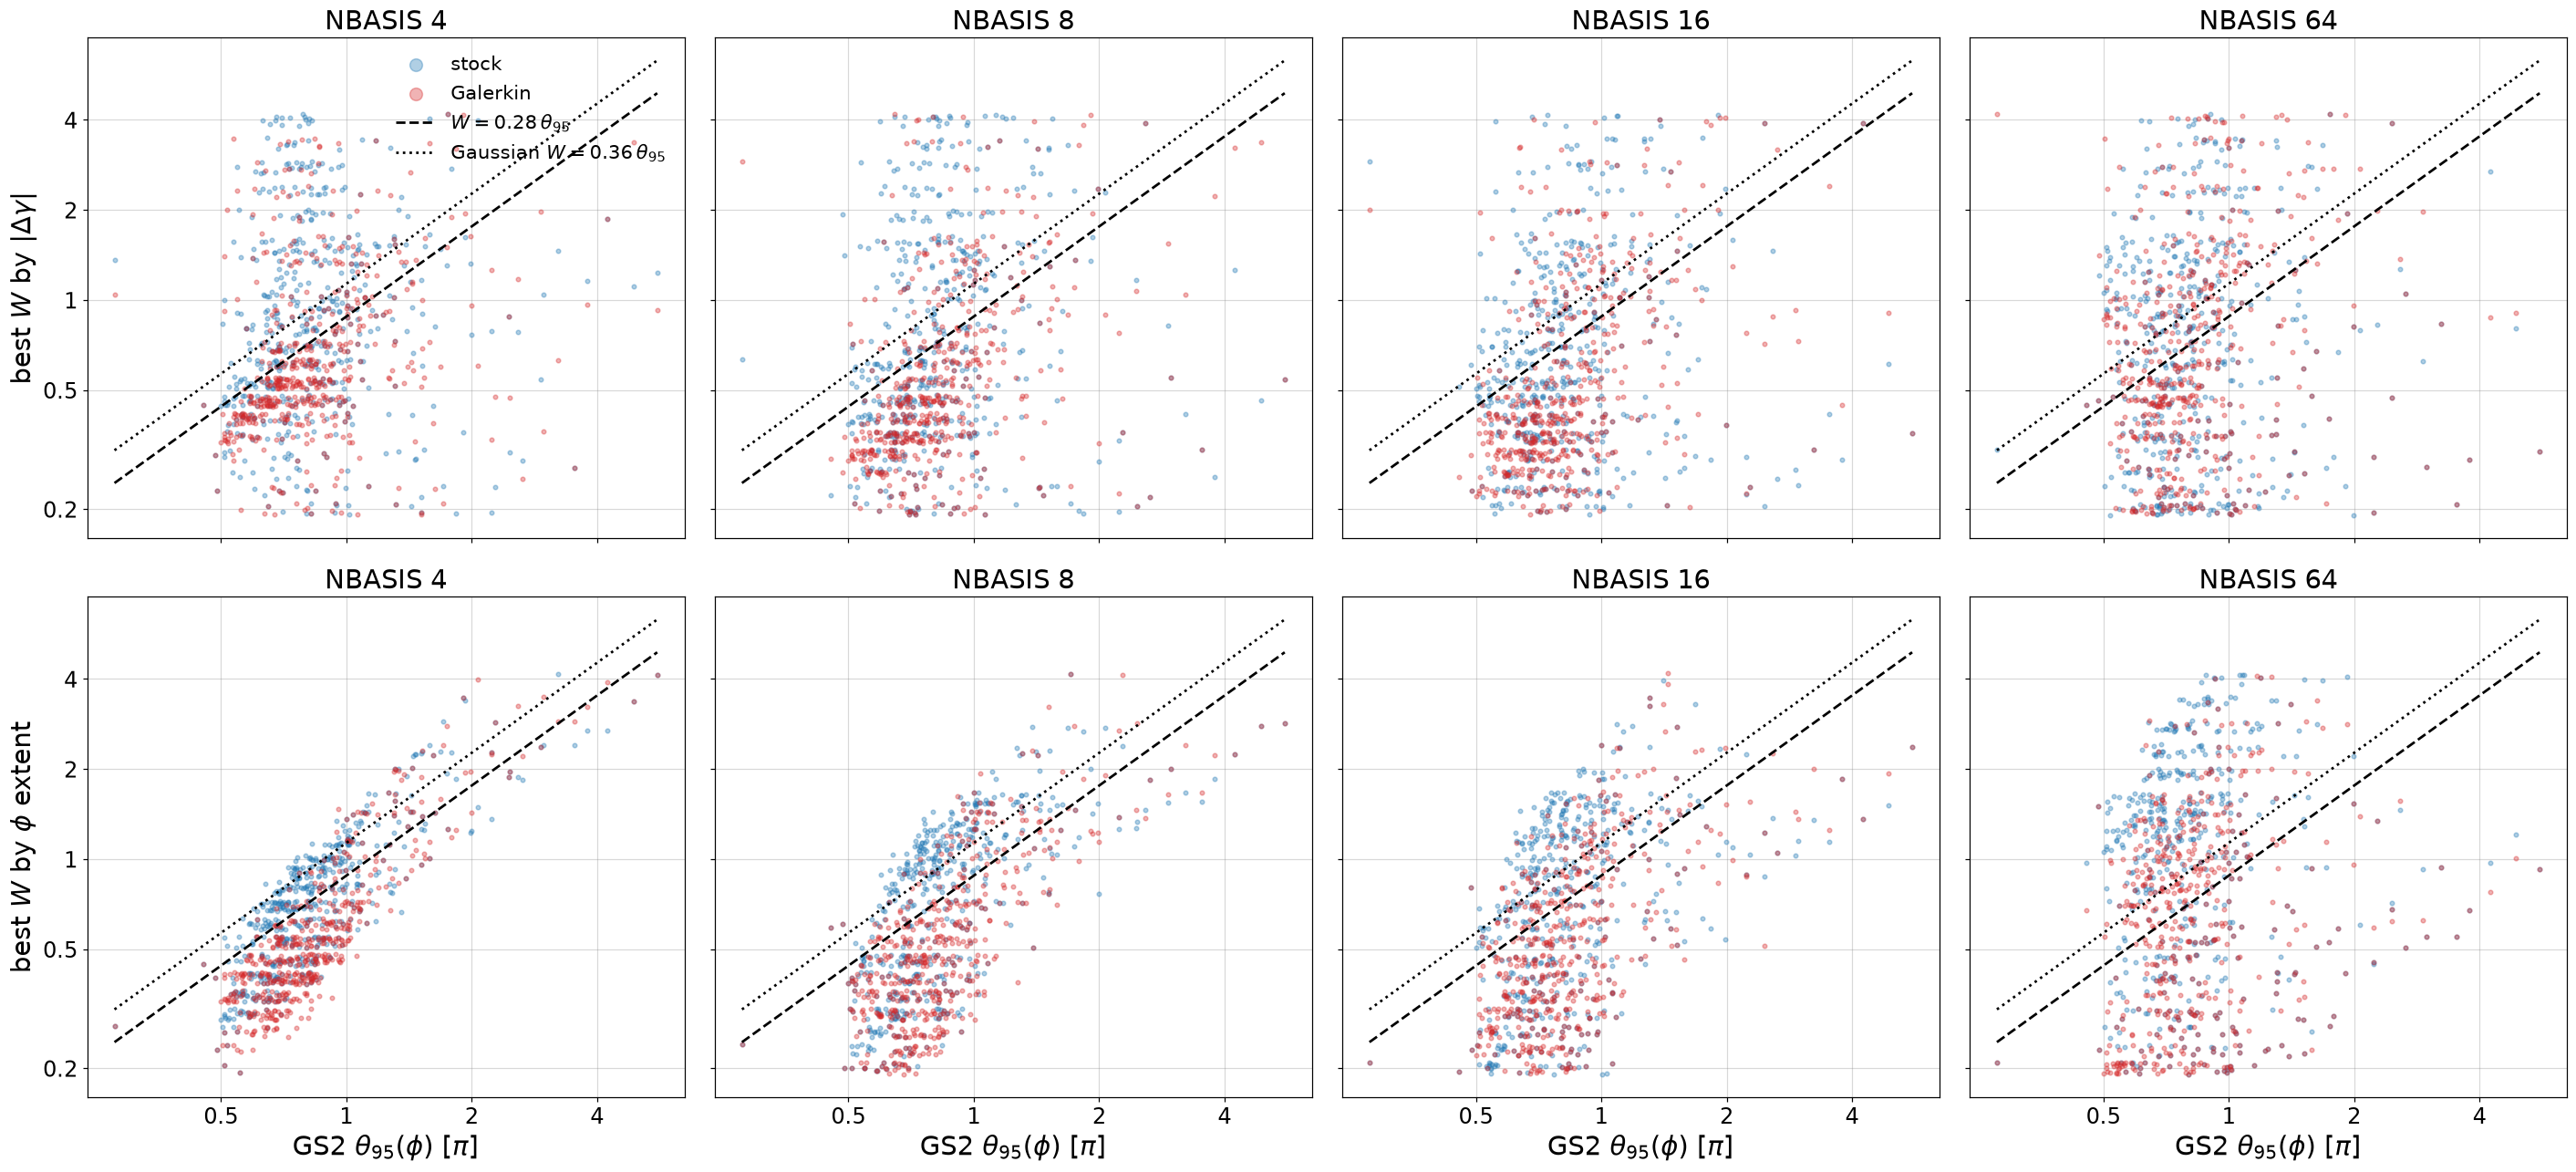

In [4]:
def best_width(error):
    # per (case, arm, N, sample): the grid width minimising `error`, and its spread with and without the theta95 normalisation
    best = data.dropna(subset=[error]).loc[lambda d: d.groupby(["case", "arm", "nbasis", "sample"])[error].idxmin()]
    return best.assign(log_w=np.log10(best.width), log_w_over_theta=np.log10(best.width / best.theta95_phi),
                       at_edge=best.width.isin(widths[[0, -1]]))


best, best_extent = best_width("gamma_error"), best_width("extent_error")
collapse_spread = pd.concat({by: d.groupby(["arm", "nbasis"]).agg(
    std_log_W=("log_w", "std"), std_log_W_over_theta95=("log_w_over_theta", "std"),
    c=("log_w_over_theta", lambda v: 10 ** v.mean()), edge_share=("at_edge", "mean"),
    corr_log_W_log_theta95=("log_w", lambda v: np.corrcoef(v, np.log10(d.loc[v.index, "theta95_phi"]))[0, 1]))
    for by, d in (("gamma", best), ("extent", best_extent))}, names=["best_by"])
c_fit = 10 ** best[best.arm == "F"].log_w_over_theta.mean()
print(f"c (stock, all N) = {c_fit:.3f}   | Gaussian c = {gaussian_c:.3f}")
print(collapse_spread.round(3).to_string())
data["s"] = data.width / (c_fit * data.theta95_phi)

# the low-level result behind the collapse: per-sample best width against theta95 (if theta95 set the width, points follow W = c theta95)
fig1b, axes1b = plt.subplots(2, 4, figsize=(26, 12), sharex=True, sharey=True)
theta_line = np.array([gs2.theta95_phi.min(), gs2.theta95_phi.max()])
for row, (by, d) in enumerate((("gamma", best), ("extent", best_extent))):
    for ax, nbasis in zip(axes1b[row], (4, 8, 16, 64)):
        for arm, colour in (("F", "C0"), ("T", "C3")):
            dd = d[(d.arm == arm) & (d.nbasis == nbasis)]
            jitter = 10 ** np.random.default_rng(0).uniform(-0.02, 0.02, len(dd))
            ax.scatter(dd.theta95_phi / np.pi, dd.width * jitter, s=9, alpha=0.35, color=colour, label=arms[arm])
        ax.plot(theta_line / np.pi, c_fit * theta_line, "k--", marker="", label=rf"$W = {c_fit:.2f}\,\theta_{{95}}$")
        ax.plot(theta_line / np.pi, gaussian_c * theta_line, "k:", marker="", label=rf"Gaussian $W = {gaussian_c:.2f}\,\theta_{{95}}$")
        ax.set(xscale="log", yscale="log", title=f"NBASIS {nbasis}")
        log_xticks(ax, [0.5, 1, 2, 4])
        ax.set_yticks([0.2, 0.5, 1, 2, 4])
        ax.yaxis.set_major_formatter(StrMethodFormatter("{x:g}"))
    axes1b[row, 0].set_ylabel(r"best $W$ by $|\Delta\gamma|$" if by == "gamma" else r"best $W$ by $\phi$ extent")
for ax in axes1b[1]:
    ax.set_xlabel(r"GS2 $\theta_{95}(\phi)$ $[\pi]$")
axes1b[0, 0].legend(markerscale=3)
fig1b.tight_layout()
fig1b.savefig(plots_dir / "fig1b_best_width_vs_theta95.png", dpi=150)
plt.show()

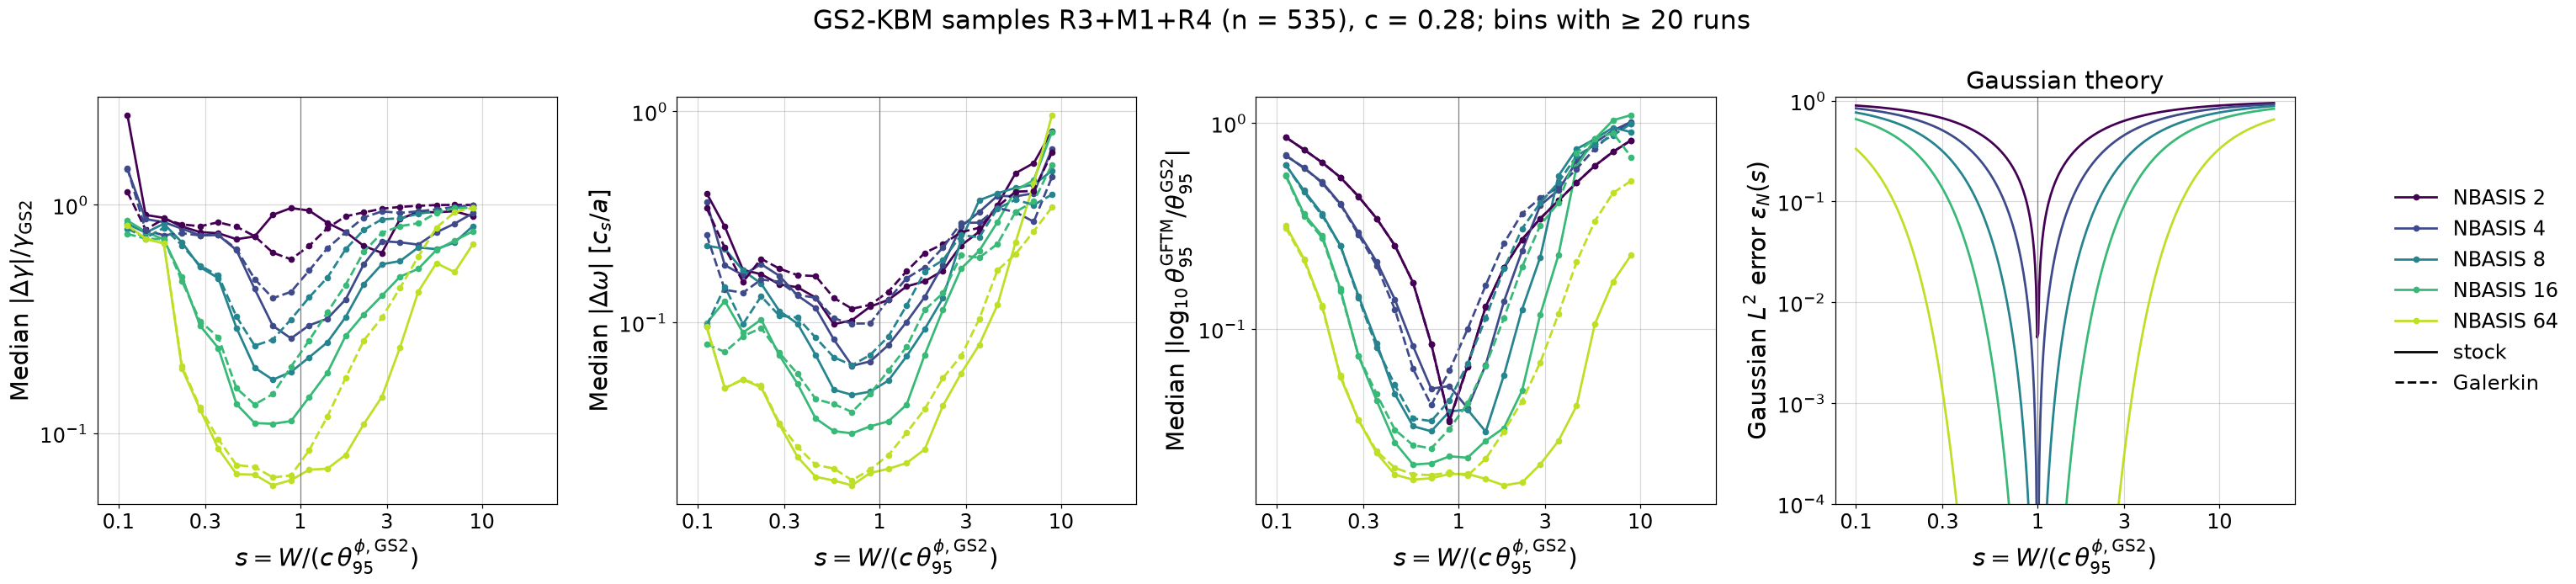

In [5]:
log_s_edges = np.arange(-1.0, 1.31, 0.1)
log_s_centres = (log_s_edges[:-1] + log_s_edges[1:]) / 2
data["log_s_bin"] = pd.cut(np.log10(data.s), log_s_edges, labels=log_s_centres)
quantities = {"gamma_error": r"Median $|\Delta\gamma|/\gamma_{\rm GS2}$", "omega_error": r"Median $|\Delta\omega|$ $[c_s/a]$",
              "extent_error": r"Median $|\log_{10}\theta_{95}^{\rm GFTM}/\theta_{95}^{\rm GS2}|$"}
binned = (data.groupby(["arm", "nbasis", "log_s_bin"], observed=True)
          .agg(n=("gamma_error", "size"), **{q: (q, "median") for q in quantities}).reset_index())
binned = binned[binned.n >= 20]      # bins with fewer runs are noise
binned["s"] = 10 ** binned.log_s_bin.astype(float)

s_plot = np.logspace(-1, 1.3, 400)
fig1, axes1 = plt.subplots(1, 4, figsize=(28, 6.5), sharex=True)
for ax, (quantity, label) in zip(axes1, quantities.items()):
    for arm, ls in (("F", "-"), ("T", "--")):
        for nbasis in nbasis_all:
            d = binned[(binned.arm == arm) & (binned.nbasis == nbasis)]
            ax.plot(d.s, d[quantity], ls=ls, color=nbasis_colours[nbasis], marker="o" if arm == "F" else None, ms=4,
                    label=f"NBASIS {nbasis}" if arm == "F" else None)
    ax.set(xscale="log", yscale="log", ylabel=label)
for nbasis in nbasis_all:
    axes1[3].plot(s_plot, gaussian_error(s_plot, nbasis), color=nbasis_colours[nbasis], marker="")
axes1[3].set(xscale="log", yscale="log", ylim=(1e-4, 1.1), ylabel=r"Gaussian $L^2$ error $\epsilon_N(s)$")
for ax in axes1:
    ax.axvline(1, color="0.5", lw=0.8, marker="")
    ax.set_xlabel(r"$s = W / (c\,\theta_{95}^{\phi,{\rm GS2}})$")
    log_xticks(ax, [0.1, 0.3, 1, 3, 10])
axes1[0].plot([], [], "k-", label="stock")
axes1[0].plot([], [], "k--", label="Galerkin")
fig1.legend(*axes1[0].get_legend_handles_labels(), loc="center right", fontsize=16)
axes1[3].set_title("Gaussian theory", fontsize=19)
fig1.suptitle(f"GS2-KBM samples {'+'.join(cases)} (n = {len(gs2)}), c = {c_fit:.2f}; bins with ≥ 20 runs", fontsize=20)
fig1.tight_layout(rect=(0, 0, 0.9, 1))
fig1.savefig(plots_dir / "fig1_collapse.png", dpi=150)
plt.show()

**Window and symmetry.** For each $(\mathrm{arm}, N)$, the contiguous range of $s$ bins around the minimum where the median
$|\Delta\gamma|/\gamma_{\rm GS2}$ stays below 10% and 20%: its edges $s_{\rm lo}, s_{\rm hi}$, its width in dex, and its
asymmetry $\log_{10}s_{\rm hi} + \log_{10}s_{\rm lo}$ (0 if symmetric about $s = 1$). An edge equal to the outermost populated bin is
censored (the window may extend further), flagged `lo_censored`/`hi_censored`. The Gaussian prediction: the window where $\epsilon_N(s) < \epsilon$
is $|r| < \epsilon^{2/N}$ approximately, symmetric in $\log s$, with $s_{\rm hi} \approx \sqrt{N/\ln(1/\epsilon)}$ at large $N$.

In [6]:
def window(s, values, threshold):
    # contiguous run of bins around the minimum with values below threshold; NaN if the minimum is above it
    s, values = np.asarray(s), np.asarray(values)
    best_bin = np.nanargmin(values)
    if values[best_bin] >= threshold:
        return np.nan, np.nan, False, False
    lo = hi = best_bin
    while lo > 0 and values[lo - 1] < threshold:
        lo -= 1
    while hi < len(values) - 1 and values[hi + 1] < threshold:
        hi += 1
    return s[lo], s[hi], lo == 0, hi == len(values) - 1


rows = []
for (arm, nbasis), d in binned.groupby(["arm", "nbasis"]):
    d = d.sort_values("s")
    for threshold in (0.1, 0.2):
        s_lo, s_hi, lo_censored, hi_censored = window(d.s, d.gamma_error, threshold)
        theory = s_plot[gaussian_error(s_plot, nbasis) < threshold]
        rows.append(dict(arm=arm, nbasis=nbasis, threshold=threshold, s_at_min=d.s.values[d.gamma_error.values.argmin()],
                         min_error=d.gamma_error.min(), s_lo=s_lo, s_hi=s_hi, lo_censored=lo_censored, hi_censored=hi_censored,
                         width_dex=np.log10(s_hi / s_lo), asymmetry_dex=np.log10(s_hi * s_lo),
                         gaussian_s_lo=theory.min(), gaussian_s_hi=theory.max()))
collapse_windows = pd.DataFrame(rows)
print(collapse_windows.round(3).to_string(index=False))

arm  nbasis  threshold  s_at_min  min_error  s_lo  s_hi  lo_censored  hi_censored  width_dex  asymmetry_dex  gaussian_s_lo  gaussian_s_hi
  F       2        0.1     2.818      0.616   NaN   NaN        False        False        NaN            NaN          0.870          1.150
  F       2        0.2     2.818      0.616   NaN   NaN        False        False        NaN            NaN          0.752          1.331
  F       4        0.1     0.891      0.260   NaN   NaN        False        False        NaN            NaN          0.658          1.520
  F       4        0.2     0.891      0.260   NaN   NaN        False        False        NaN            NaN          0.540          1.854
  F       8        0.1     0.708      0.172   NaN   NaN        False        False        NaN            NaN          0.466          2.146
  F       8        0.2     0.708      0.172 0.562 0.891        False        False        0.2           -0.3          0.377          2.653
  F      16        0.1     0.708  

## 2. Field width ratios in GS2
$\rho_A = \theta_{95}(A_\parallel)/\theta_{95}(\phi)$, $\rho_B = \theta_{95}(B_\parallel)/\theta_{95}(\phi)$, and the ratio of the $\sigma$
($|B_\parallel|^2/k_\perp^2$) extent to the $B_\parallel$ extent. Two fields of widths $\sigma_1$, $\sigma_2 = \rho\sigma_1$ share one basis; the
best common $W$ is the geometric mean, which puts both at mismatch $s = \sqrt{\rho}$, so $N_{\min} = N_\epsilon(\sqrt{\rho}) \approx \rho\ln(1/\epsilon)$.

         ratio  p10  median  p90  N_min_eps0.1_median  N_min_eps0.01_median  N_min_eps0.1_p90  N_min_eps0.01_p90
         rho_A 0.61    0.93 1.25                 1.94                  3.88              3.25               6.50
         rho_B 0.55    0.88 0.98                 1.71                  3.42              3.81               7.61
  sigma_over_B 0.42    0.63 0.79                 3.10                  6.19              5.14              10.29
sigma_over_phi 0.28    0.52 0.71                 3.96                  7.93              8.07              16.15
median theta95 [pi] by case:
       theta95_phi  theta95_apar  theta95_bpar  theta95_sigma
case                                                        
M1          0.822         0.806         0.669          0.467
R3          0.778         0.771         0.672          0.435
R4          0.774         0.700         0.640          0.377


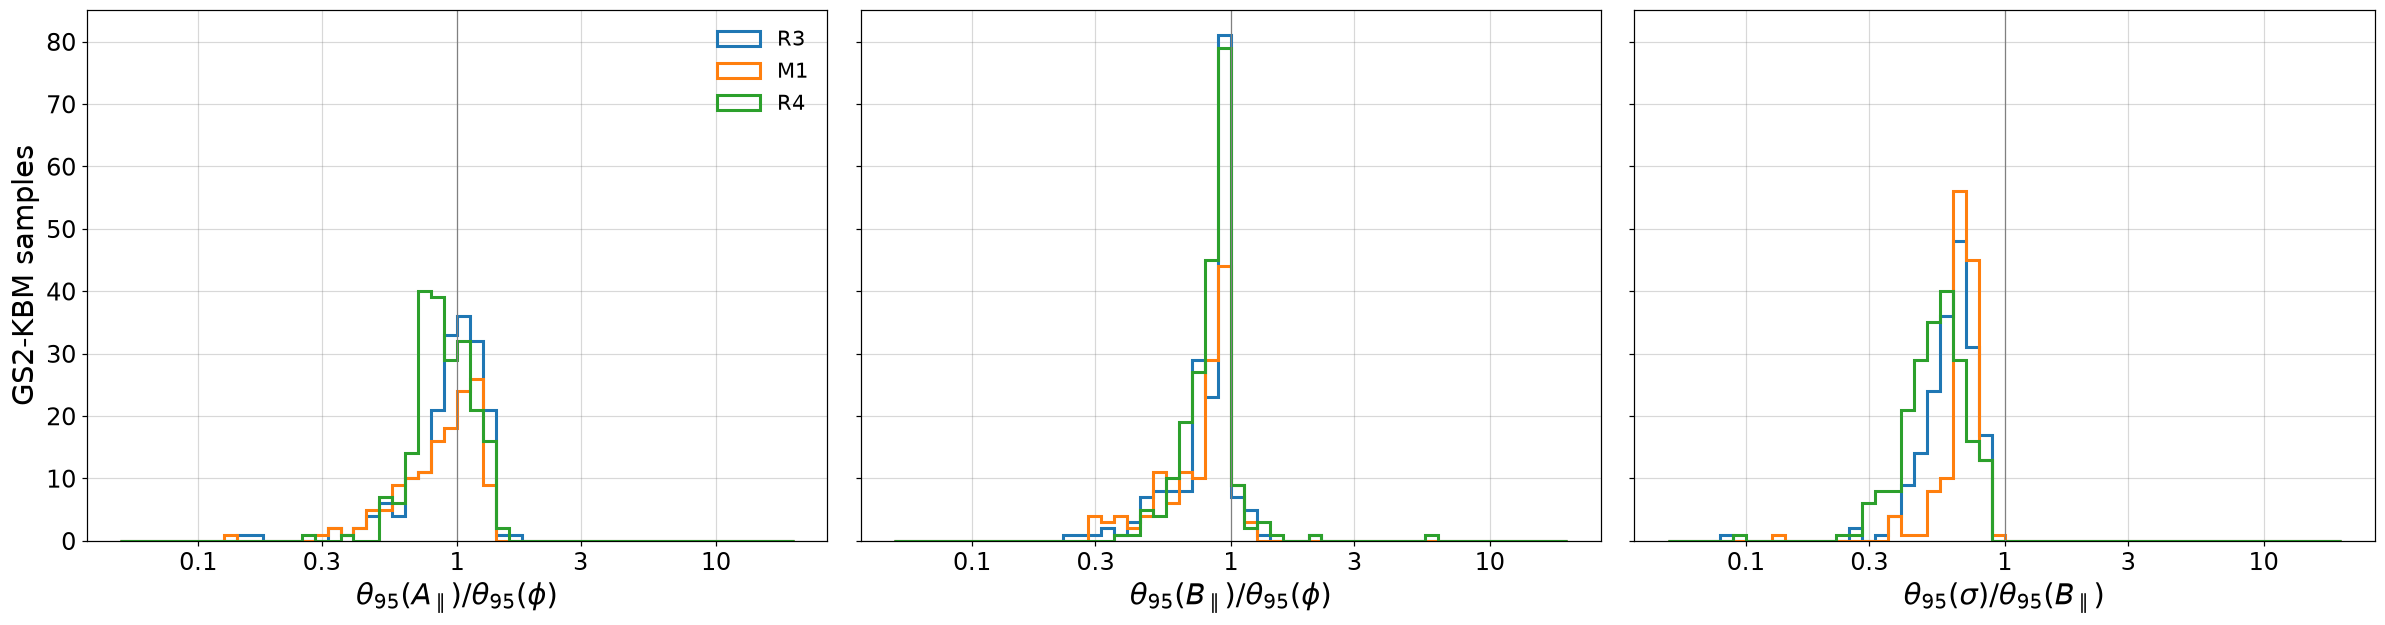

In [7]:
gs2["rho_A"] = gs2.theta95_apar / gs2.theta95_phi
gs2["rho_B"] = gs2.theta95_bpar / gs2.theta95_phi
gs2["sigma_over_B"] = gs2.theta95_sigma / gs2.theta95_bpar
gs2["sigma_over_phi"] = gs2.theta95_sigma / gs2.theta95_phi
ratios = {"rho_A": r"$\theta_{95}(A_\parallel)/\theta_{95}(\phi)$", "rho_B": r"$\theta_{95}(B_\parallel)/\theta_{95}(\phi)$",
          "sigma_over_B": r"$\theta_{95}(\sigma)/\theta_{95}(B_\parallel)$"}
rows = []
for ratio in [*ratios, "sigma_over_phi"]:
    values = gs2[ratio]
    rho = np.maximum(values, 1 / values)        # mismatch is symmetric: a narrower field costs the same as a wider one
    rows.append(dict(ratio=ratio, p10=values.quantile(0.1), median=values.median(), p90=values.quantile(0.9),
                     **{f"N_min_eps{eps:g}_median": np.median(n_epsilon(np.sqrt(rho), eps)) for eps in (0.1, 0.01)},
                     **{f"N_min_eps{eps:g}_p90": np.quantile(n_epsilon(np.sqrt(rho), eps), 0.9) for eps in (0.1, 0.01)}))
field_ratios = pd.DataFrame(rows)
print(field_ratios.round(2).to_string(index=False))
print("median theta95 [pi] by case:\n", (gs2.groupby("case")[["theta95_phi", "theta95_apar", "theta95_bpar", "theta95_sigma"]].median() / np.pi).round(3).to_string())

fig2, axes2 = plt.subplots(1, 3, figsize=(22, 6), sharey=True)
bins = np.logspace(-1.3, 1.3, 53)
for ax, (ratio, label) in zip(axes2, ratios.items()):
    for case, colour in zip(cases, ("C0", "C1", "C2")):
        ax.hist(gs2[gs2.case == case][ratio], bins=bins, histtype="step", lw=2, color=colour, label=case)
    ax.axvline(1, color="0.5", lw=0.8, marker="")
    ax.set(xscale="log", xlabel=label)
    log_xticks(ax, [0.1, 0.3, 1, 3, 10])
axes2[0].set_ylabel("GS2-KBM samples")
axes2[0].legend()
fig2.tight_layout()
fig2.savefig(plots_dir / "fig2_field_width_ratios.png", dpi=150)
plt.show()

## 3. Validity window of the recommended fixed widths
The fixed settings recommended by `qp5.25` (LODO table): stock W 0.40 at NBASIS 16; stock W 0.46 and 0.53 at NBASIS 64; Galerkin W 0.46 at
NBASIS 64 (nearest grid width). Median $|\Delta\gamma|/\gamma_{\rm GS2}$ in deciles of GS2 $\theta_{95}(\phi)$ (equal-count bins, pooled),
and the contiguous $\theta_{95}$ range around the best bin where it stays below 10% and 20%.

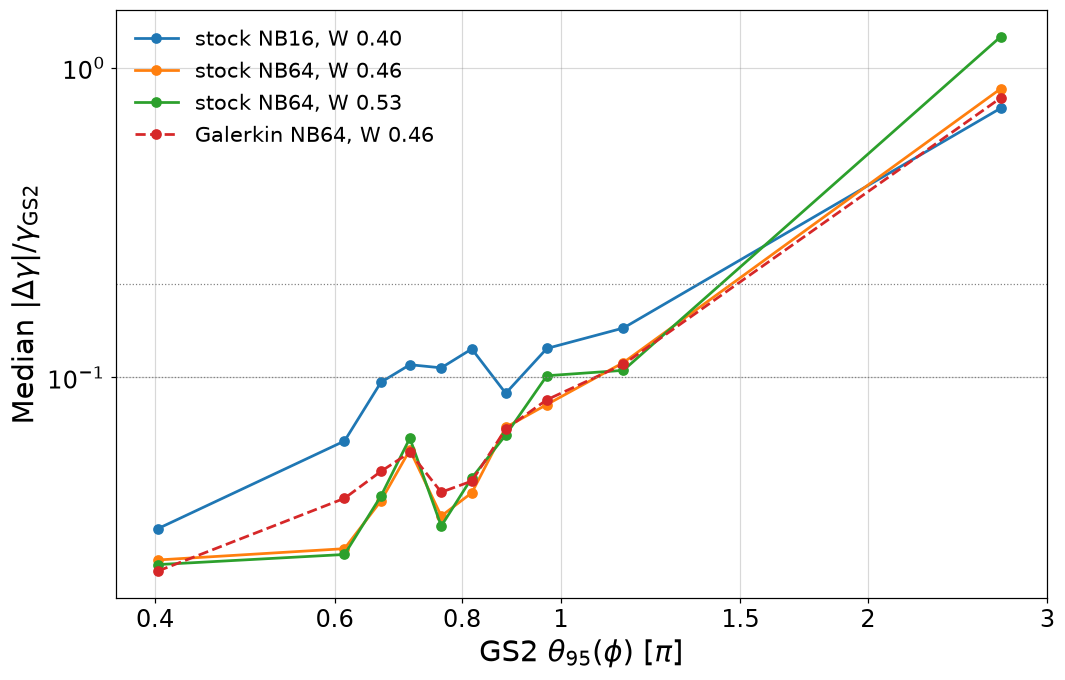

              setting  threshold  theta95_lo_pi  theta95_hi_pi  s_lo  s_hi  overall_median  share_of_samples_inside  share_inside_R3  share_inside_M1  share_inside_R4
   stock NB16, W 0.40        0.1          0.278          0.689 0.659 1.636           0.111                    0.301            0.337            0.200            0.337
   stock NB16, W 0.40        0.2          0.278          1.306 0.348 1.636           0.111                    0.899            0.888            0.821            0.962
   stock NB64, W 0.46        0.1          0.278          1.015 0.514 1.879           0.057                    0.800            0.775            0.700            0.889
   stock NB64, W 0.46        0.2          0.278          1.306 0.399 1.879           0.057                    0.899            0.888            0.821            0.962
   stock NB64, W 0.53        0.1          0.278          0.925 0.648 2.159           0.059                    0.699            0.668            0.600            0.79

In [8]:
fixed_settings = [("F", 16, 0.40), ("F", 64, 0.46), ("F", 64, 0.53), ("T", 64, 0.46)]
theta_edges = np.quantile(gs2.theta95_phi, np.linspace(0, 1, 11))
data["theta_bin"] = pd.cut(data.theta95_phi, theta_edges, include_lowest=True, labels=False)
theta_centres = np.sqrt(theta_edges[:-1] * theta_edges[1:])
rows, validity = [], []
fig3, ax3 = plt.subplots(figsize=(10, 6.5))
for (arm, nbasis, width), colour in zip(fixed_settings, ("C0", "C1", "C2", "C3")):
    grid_width = widths[np.abs(np.log10(widths / width)).argmin()]
    d = data[(data.arm == arm) & (data.nbasis == nbasis) & (data.width == grid_width)]
    median = d.groupby("theta_bin").gamma_error.median().reindex(range(10)).values
    label = f"{arms[arm]} NB{nbasis}, W {grid_width:.2f}"
    ax3.plot(theta_centres / np.pi, median, marker="o", color=colour, ls="--" if arm == "T" else "-", label=label)
    rows += [dict(setting=label, theta95_bin_lo_pi=lo / np.pi, theta95_bin_hi_pi=hi / np.pi,
                  s_at_bin_centre=grid_width / (c_fit * centre), n=int((d.theta_bin == k).sum()), median_gamma_error=m)
             for k, (lo, hi, centre, m) in enumerate(zip(theta_edges[:-1], theta_edges[1:], theta_centres, median))]
    for threshold in (0.1, 0.2):
        lo_index, hi_index, _, _ = window(np.arange(10), median, threshold)
        inside = (np.nan, np.nan) if np.isnan(lo_index) else (theta_edges[int(lo_index)], theta_edges[int(hi_index) + 1])
        validity.append(dict(setting=label, threshold=threshold, theta95_lo_pi=inside[0] / np.pi, theta95_hi_pi=inside[1] / np.pi,
                             s_lo=grid_width / (c_fit * inside[1]), s_hi=grid_width / (c_fit * inside[0]),
                             overall_median=d.gamma_error.median(),
                             share_of_samples_inside=np.mean((gs2.theta95_phi >= inside[0]) & (gs2.theta95_phi <= inside[1])),
                             **{f"share_inside_{case}": np.mean((gs2[gs2.case == case].theta95_phi >= inside[0]) &
                                                                (gs2[gs2.case == case].theta95_phi <= inside[1])) for case in cases}))
for threshold in (0.1, 0.2):
    ax3.axhline(threshold, color="0.5", lw=0.8, ls=":", marker="")
ax3.set(xscale="log", yscale="log", xlabel=r"GS2 $\theta_{95}(\phi)$ $[\pi]$", ylabel=r"Median $|\Delta\gamma|/\gamma_{\rm GS2}$")
log_xticks(ax3, [0.4, 0.6, 0.8, 1, 1.5, 2, 3])
ax3.legend()
fig3.tight_layout()
fig3.savefig(plots_dir / "fig3_validity_window.png", dpi=150)
plt.show()
validity_bins, validity_window = pd.DataFrame(rows), pd.DataFrame(validity)
print(validity_window.round(3).to_string(index=False))
print("theta95(phi) [pi] p5/p50/p95 by case:\n", gs2.groupby("case").theta95_phi.quantile([0.05, 0.5, 0.95]).unstack().div(np.pi).round(2).to_string())

## 4. Cost law
Wall time per run = mtime(`out.gftm.run`) − mtime(`out.gftm.localdump`) (as section 5 of the parent notebook; whole-second timestamps, so
the NBASIS ≤ 8 means are resolved to about ±0.01 s). Power law $t \propto N^p$ fitted on NBASIS 4, 8, 16 (all NXGRID 32; NBASIS 2 is at the
timestamp floor), then extrapolated to NBASIS 64, which ran at NXGRID 65: the measured/extrapolated ratio is the NXGRID cost on top of $N$.
Combined: $t(N_\epsilon(s))$ with $N_\epsilon$ from the Gaussian law, rounded up, floor 1.

arm          F       T
nbasis                
2        0.019   0.018
4        0.036   0.034
8        0.126   0.129
16       0.772   0.779
64      44.959  43.327
t ~ N^2.24 on NB 4-16 (NX32); NB64: measured 44.1 s, extrapolated 15.84 s, ratio 2.8 (NXGRID 32->65 and anything else not in N^p)
two-point exponent NB16(NX32) -> NB64(NX65): 2.92


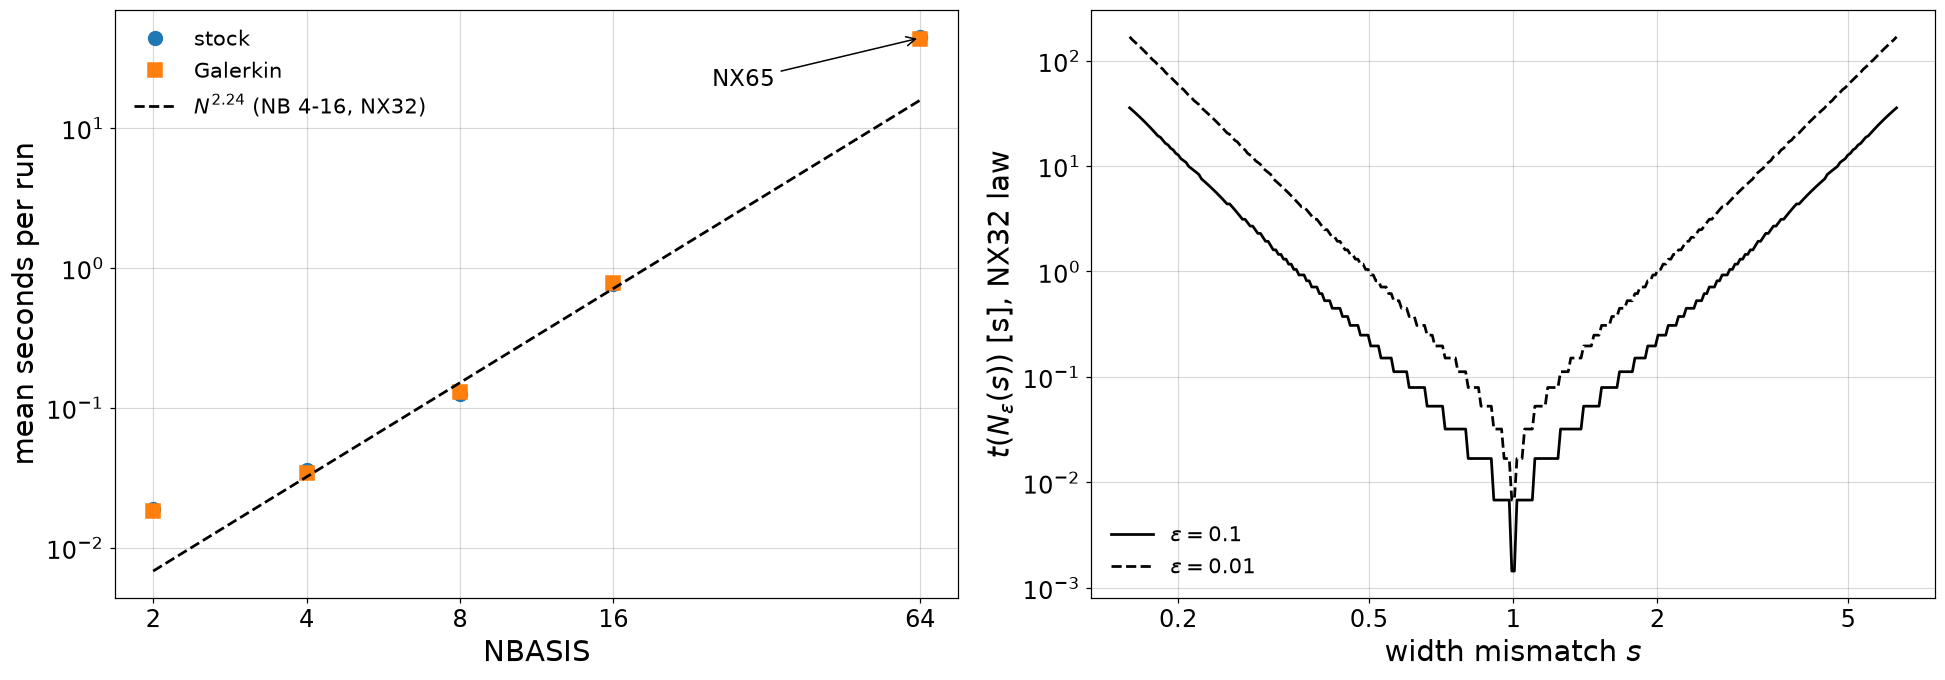

In [9]:
def run_seconds(leaf):
    names = gftm[gftm.case == leaf.parent.parent.name]["sample"].unique()
    return [(leaf.name[3], int(leaf.name.split("_nb")[1].split("_")[0]),
             (leaf / name / "out.gftm.run").stat().st_mtime - (leaf / name / "out.gftm.localdump").stat().st_mtime) for name in names]


with get_context("fork").Pool(n_workers) as pool:
    timing = pd.DataFrame([row for rows in pool.map(run_seconds, leaves, chunksize=4) for row in rows], columns=["arm", "nbasis", "seconds"])
solve_seconds = timing.groupby(["arm", "nbasis"]).seconds.mean().unstack(0)
print(solve_seconds.round(3).to_string())
fit_nbasis = [4, 8, 16]
p_fit, log_a = np.polyfit(np.log(fit_nbasis), np.log(solve_seconds.loc[fit_nbasis].mean(1)), 1)
extrapolated_64 = np.exp(log_a) * 64 ** p_fit
print(f"t ~ N^{p_fit:.2f} on NB 4-16 (NX32); NB64: measured {solve_seconds.loc[64].mean():.1f} s, extrapolated {extrapolated_64:.2f} s, "
      f"ratio {solve_seconds.loc[64].mean() / extrapolated_64:.1f} (NXGRID 32->65 and anything else not in N^p)")
p_64 = np.log(solve_seconds.loc[64].mean() / solve_seconds.loc[16].mean()) / np.log(4)
print(f"two-point exponent NB16(NX32) -> NB64(NX65): {p_64:.2f}")

fig4, axes4 = plt.subplots(1, 2, figsize=(18, 6.5))
for arm, marker in (("F", "o"), ("T", "s")):
    axes4[0].plot(solve_seconds.index, solve_seconds[arm], marker=marker, ls="none", ms=9, label=arms[arm])
n_line = np.logspace(np.log10(2), np.log10(64), 50)
axes4[0].plot(n_line, np.exp(log_a) * n_line ** p_fit, "k--", marker="", label=f"$N^{{{p_fit:.2f}}}$ (NB 4-16, NX32)")
axes4[0].set(xscale="log", yscale="log", xlabel="NBASIS", ylabel="mean seconds per run")
axes4[0].annotate("NX65", (64, solve_seconds.loc[64].mean()), xytext=(25, 20), fontsize=15, arrowprops=dict(arrowstyle="->"))
log_xticks(axes4[0], nbasis_all)
axes4[0].legend()
s_cost = np.logspace(-0.8, 0.8, 300)
for eps, ls in ((0.1, "-"), (0.01, "--")):
    n_needed = np.maximum(1, np.ceil(n_epsilon(s_cost, eps)))
    axes4[1].plot(s_cost, np.exp(log_a) * n_needed ** p_fit, "k", ls=ls, marker="", label=rf"$\epsilon = {eps:g}$")
axes4[1].set(xscale="log", yscale="log", xlabel=r"width mismatch $s$", ylabel=r"$t(N_\epsilon(s))$ [s], NX32 law")
log_xticks(axes4[1], [0.2, 0.5, 1, 2, 5])
axes4[1].legend()
fig4.tight_layout()
fig4.savefig(plots_dir / "fig4_cost_law.png", dpi=150)
plt.show()

## Summary tables (small, no per-sample rows) for Fusion_PhD `results/kbm_width_collapse/csv/`

In [10]:
csv_dir = plots_dir / "csv"
csv_dir.mkdir(exist_ok=True)
collapse_spread.reset_index().to_csv(csv_dir / "collapse_spread.csv", index=False, float_format="%.4g")
collapse_windows.to_csv(csv_dir / "collapse_windows.csv", index=False, float_format="%.4g")
binned.drop(columns="log_s_bin").to_csv(csv_dir / "collapse_binned_medians.csv", index=False, float_format="%.4g")
field_ratios.to_csv(csv_dir / "field_width_ratios.csv", index=False, float_format="%.4g")
validity_window.to_csv(csv_dir / "validity_window.csv", index=False, float_format="%.4g")
validity_bins.to_csv(csv_dir / "validity_bins.csv", index=False, float_format="%.4g")
solve_seconds.reset_index().to_csv(csv_dir / "solve_seconds.csv", index=False, float_format="%.4g")
json.dump(dict(c_fit=c_fit, gaussian_c=gaussian_c, cost_exponent_nb4_16=p_fit, cost_exponent_nb16_64=p_64,
               nb64_measured_over_extrapolated=float(solve_seconds.loc[64].mean() / extrapolated_64),
               population={case: int((gs2.case == case).sum()) for case in cases}),
          open(csv_dir / "summary.json", "w"), indent=1)
print(sorted(path.name for path in csv_dir.iterdir()))

['collapse_binned_medians.csv', 'collapse_spread.csv', 'collapse_windows.csv', 'field_width_ratios.csv', 'solve_seconds.csv', 'summary.json', 'validity_bins.csv', 'validity_window.csv']
